<a href="https://colab.research.google.com/github/bibhupada-sahoo/tess-transit-mcmc-pipeline/blob/main/notebooks/wasp18b_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!pip install -q lightkurve emcee corner

In [6]:
import os
import numpy as np
import lightkurve as lk

# Download 2-minute cadence NASA TESS data for WASP-18 b
search = lk.search_lightcurve("WASP-18", mission="TESS", author="SPOC", exptime=120, sector=2)
lc = search[0].download().remove_nans().normalize()
flat_lc = lc.flatten(window_length=401).remove_outliers(sigma=5)

time = np.asarray(flat_lc.time.value, dtype=float)
flux = np.asarray(flat_lc.flux.value, dtype=float)
flux_err = np.asarray(flat_lc.flux_err.value, dtype=float)

# Automatic Box Least Squares (BLS) period search
bls = flat_lc.to_periodogram(method="bls", period=np.linspace(0.5, 2.0, 5000))
period = float(bls.period_at_max_power.value)
t0_bls = float(bls.transit_time_at_max_power.value)
depth_bls = float(bls.depth_at_max_power.value)

print(f"Detected Period: {period:.6f} days | Epoch T0: {t0_bls:.5f} | Depth: {depth_bls:.5f}")

Detected Period: 0.941688 days | Epoch T0: 1354.45151 | Depth: 0.00771


In [7]:
import matplotlib.pyplot as plt
import emcee
import corner

def quadratic_ld_transit(time, t0, period, rp_rs, a_rs, inc_deg, u1=0.30, u2=0.25, n_rings=100):
    flux = np.ones_like(time, dtype=float)
    phase = ((time - t0 + 0.5 * period) % period) / period - 0.5
    near = np.abs(phase) < 0.25
    if not np.any(near):
        return flux

    phi = 2.0 * np.pi * phase[near]
    inc = np.radians(inc_deg)
    z = a_rs * np.sqrt(np.sin(phi)**2 + (np.cos(inc) * np.cos(phi))**2)

    dr = 1.0 / n_rings
    r = (np.arange(n_rings) + 0.5) * dr
    mu = np.sqrt(1.0 - r**2)
    intensity = 1.0 - u1 * (1.0 - mu) - u2 * (1.0 - mu)**2
    ring_area = 2.0 * np.pi * r * dr
    total_flux = np.sum(intensity * ring_area)

    z_col = z[:, None]
    r_row = r[None, :]
    covered = np.zeros((len(z), n_rings), dtype=float)

    full_cover = (rp_rs - z_col) >= r_row
    covered[full_cover] = 1.0

    partial = (~full_cover) & (np.abs(z_col - rp_rs) < r_row) & (r_row < (z_col + rp_rs))
    if np.any(partial):
        z_p = np.broadcast_to(z_col, covered.shape)[partial]
        r_p = np.broadcast_to(r_row, covered.shape)[partial]
        cos_alpha = np.clip((r_p**2 + z_p**2 - rp_rs**2) / (2.0 * r_p * z_p), -1.0, 1.0)
        covered[partial] = np.arccos(cos_alpha) / np.pi

    blocked_flux = np.sum(covered * (intensity * ring_area)[None, :], axis=1)
    flux[near] = 1.0 - blocked_flux / total_flux
    return flux

phase_days = ((time - t0_bls + 0.5 * period) % period) - 0.5 * period
mask = np.abs(phase_days) < 0.15
t_fit, f_fit, err_fit = time[mask], flux[mask], flux_err[mask]

def log_probability(theta):
    dt0, rp_rs, a_rs, inc = theta
    if not (-0.02 < dt0 < 0.02 and 0.01 < rp_rs < 0.25 and 2.0 < a_rs < 10.0 and 75.0 < inc < 90.0):
        return -np.inf
    model = quadratic_ld_transit(t_fit, t0_bls + dt0, period, rp_rs, a_rs, inc)
    return -0.5 * np.sum(((f_fit - model) / err_fit) ** 2)

pos = np.array([0.0, np.sqrt(depth_bls), 3.4, 84.5]) + 1e-3 * np.random.randn(24, 4)
sampler = emcee.EnsembleSampler(24, 4, log_probability)
sampler.run_mcmc(pos, 1000, progress=True)

samples = sampler.get_chain(discard=300, flat=True)
dt0_med, rp_med, a_med, inc_med = np.median(samples, axis=0)
dt0_err, rp_err, a_err, inc_err = np.std(samples, axis=0)

print("\n--- COPY THESE RESULTS FOR YOUR README ---")
print(f"Period      = {period:.6f} days")
print(f"Rp / R*     = {rp_med:.4f} +/- {rp_err:.4f}")
print(f"a / R*      = {a_med:.3f} +/- {a_err:.3f}")
print(f"Inclination = {inc_med:.2f} +/- {inc_err:.2f} deg")

100%|██████████| 1000/1000 [01:28<00:00, 11.26it/s]


--- COPY THESE RESULTS FOR YOUR README ---
Period      = 0.941688 days
Rp / R*     = 0.0947 +/- 0.0001
a / R*      = 3.486 +/- 0.002
Inclination = 84.58 +/- 0.02 deg


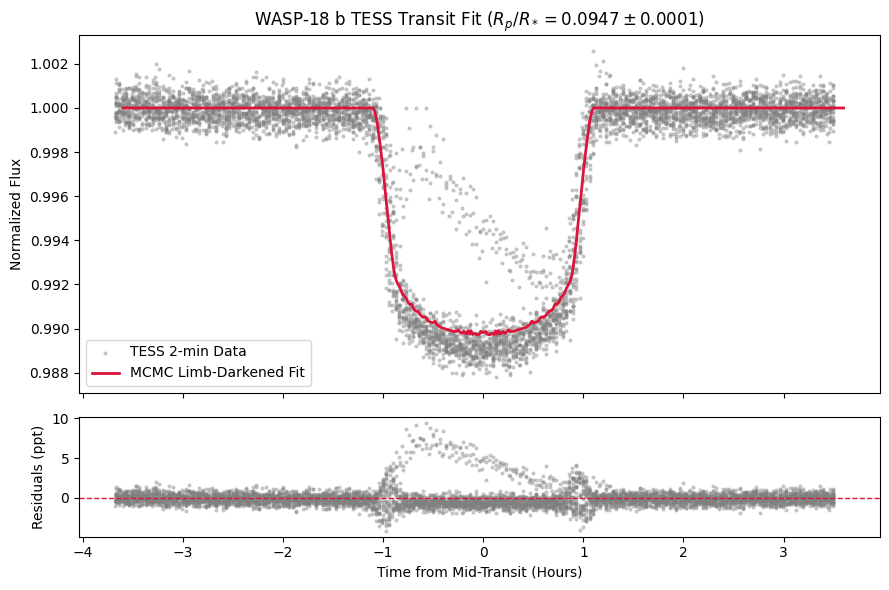

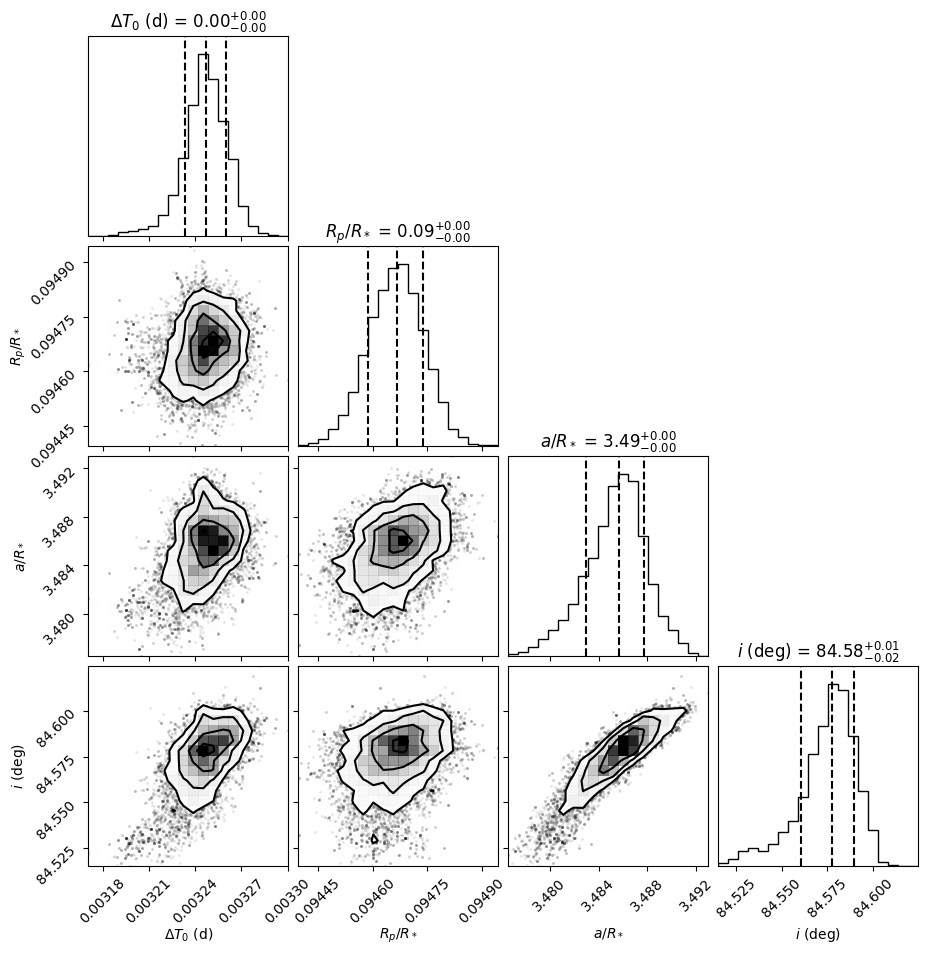

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
from google.colab import files

os.makedirs("figures", exist_ok=True)
best_t0 = t0_bls + dt0_med
phase_hrs = (((t_fit - best_t0 + 0.5 * period) % period) - 0.5 * period) * 24.0
t_grid = np.linspace(best_t0 - 0.15, best_t0 + 0.15, 500)
model_grid = quadratic_ld_transit(t_grid, best_t0, period, rp_med, a_med, inc_med)
residuals = f_fit - quadratic_ld_transit(t_fit, best_t0, period, rp_med, a_med, inc_med)

# Plot 1: Phase-folded transit + residuals
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.scatter(phase_hrs, f_fit, s=4, color="gray", alpha=0.35, label="TESS 2-min Data")
ax1.plot((t_grid - best_t0) * 24.0, model_grid, color="crimson", lw=2, label="MCMC Limb-Darkened Fit")
ax1.set_ylabel("Normalized Flux")
ax1.set_title(f"WASP-18 b TESS Transit Fit ($R_p/R_* = {rp_med:.4f} \\pm {rp_err:.4f}$)")
ax1.legend()

ax2.scatter(phase_hrs, residuals * 1e3, s=4, color="gray", alpha=0.35)
ax2.axhline(0, color="crimson", ls="--", lw=1)
ax2.set_ylabel("Residuals (ppt)")
ax2.set_xlabel("Time from Mid-Transit (Hours)")
plt.tight_layout()
plt.savefig("figures/phase_folded_fit.png", dpi=200)
plt.show()

# Plot 2: Corner plot
fig_corner = corner.corner(
    samples,
    labels=[r"$\Delta T_0$ (d)", r"$R_p/R_*$", r"$a/R_*$", r"$i$ (deg)"],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
)
fig_corner.savefig("figures/mcmc_corner.png", dpi=200)
plt.show()

files.download("figures/phase_folded_fit.png")
files.download("figures/mcmc_corner.png")